In [1]:
import os
import operator
from pydantic import BaseModel, Field
from typing import Literal, Annotated, List, Dict, Any, TypedDict, Optional
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage, AnyMessage
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.runnables import RunnableConfig
from langgraph.types import Command
from dotenv import load_dotenv
from langgraph.checkpoint.postgres import PostgresSaver
from psycopg_pool import AsyncConnectionPool
from psycopg import (
    AsyncConnection,
    sql
)
from psycopg.rows import (
    DictRow,
    dict_row
)
from langgraph.checkpoint.postgres.aio import AsyncPostgresSaver

load_dotenv()


True

In [2]:
api_key = os.getenv("NOVITA_API_KEY")
api_key

'1bd4632c-161e-4fb1-be9a-79937085ddfc'

In [3]:
PostgresConnPool = AsyncConnectionPool[AsyncConnection[DictRow]]
_connection_pool: Optional[PostgresConnPool] = None

In [4]:

async def _get_connection_pool() -> Optional[PostgresConnPool]:
        """Get a PostgreSQL connection pool.

        Returns:
            AsyncConnectionPool or None when the pool fails to initialise in
            a reasonable time.
        """
        global _connection_pool
        if _connection_pool is None:
            try:
                # Configure pool size based on environment
                max_size = int(os.getenv("POSTGRES_POOL_SIZE", "10"))

                connection_url = os.getenv("DATABASE_URL")
                
                _connection_pool = AsyncConnectionPool(
                    connection_url,
                    open=False,
                    max_size=max_size,
                    kwargs={
                        "autocommit": True,
                        "connect_timeout": 5,
                        "prepare_threshold": None,
                        "row_factory": dict_row,
                    },
                )
                await _connection_pool.open()
                print(f"connection_pool_created max_size={max_size}")
            except Exception as e:
                print(f"connection_pool_creation_failed error={str(e)}")
                raise e
        return _connection_pool

In [5]:


class MentorState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]
    problem_description: str
    current_phase: Literal["IDEATION", "CODING"]
    code_submission: Optional[str]


class IntentClassification(BaseModel):
    intent: Literal["chat", "stuck", "submit"]
    reasoning: str

class ApprovePlan(BaseModel):
    """Call this ONLY when the user has clearly stated:
    (1) a valid algorithmic approach, AND
    (2) the correct time and space complexity.
    Both conditions must be met before calling."""
    rationale: str = Field(
        description="One sentence: what the user got right that earns the unlock."
    )



def get_llm(model: str, api_base: str, temperature: float = 0.4):
    return ChatOpenAI(
        model=model, 
        temperature=temperature,
        openai_api_key=api_key,
        base_url=api_base,
        max_retries=5,
        timeout=60,
    )



def ideation_node(state: MentorState):
    """Socratic mentor. Asks one question at a time. Gate: ApprovePlan tool."""

    llm = get_llm(model="google/gemma-4-26b-a4b-it",api_base="https://api.novita.ai/openai", temperature=0.4).bind_tools([ApprovePlan])

    system = SystemMessage(content=(
        f"You are an expert DSA interviewer mentoring a candidate on this problem:\n"
        f"<problem>{state['problem_description']}</problem>\n\n"
        "RULES — follow them strictly:\n"
        "1. The code editor is LOCKED. The candidate must earn it by thinking first.\n"
        "2. NEVER write code. NEVER reveal the algorithm name unprompted.\n"
        "3. Ask EXACTLY ONE guiding question per turn. Not two. Not a question and a hint. One.\n"
        "4. Use the Socratic method: ask questions that lead them to discover the answer.\n"
        "5. When the candidate has clearly stated BOTH a valid approach AND correct "
        "   time/space complexity — call `ApprovePlan` immediately. Not before.\n"
        "6. If they are close but incomplete, ask a follow-up to close the gap."
    ))

    response = llm.invoke([system] + state["messages"])
    return {"messages": [response]} 


def route_after_ideation(state: MentorState) -> Literal["transition_node", "__end__"]:
    last = state["messages"][-1]
    tool_calls = getattr(last, "tool_calls", None) or []
    for tc in tool_calls:
        if tc["name"] == "ApprovePlan":
            return "transition_node"
    return END


def transition_node(state: MentorState):
    """
    Fires when ApprovePlan is called.
    - Satisfies the ToolMessage the LLM expects
    - Sets current_phase to CODING
    - Sends unlock message to client
    - Goes to END so client can render the editor before coding starts
    """
    last_msg = state["messages"][-1]
    tool_call = last_msg.tool_calls[0]

    tool_msg = ToolMessage(
        content="Plan approved. Transitioning to coding phase.",
        tool_call_id=tool_call["id"]
    )
    
    ai_msg = AIMessage(
        content=(
            "Perfect. Your approach is solid and your complexity analysis is correct. "
            "I've unlocked the code editor — let's see your implementation. "
            "I'm here if you get stuck."
        )
    )

    return {
        "current_phase": "CODING",
        "messages": [tool_msg, ai_msg]
    }


def intent_router(state: MentorState) -> Literal["chat_node", "hint_node", "review_node"]:
    """
    Thin classifier that runs at the start of every coding-phase turn.
    
    Deterministic short-circuits run first (no LLM cost).
    Only falls through to the tiny LLM call when genuinely ambiguous.
    """

    # Short-circuit 1: submit button was clicked — deterministic, no LLM needed
    if state.get("code_submission"):
        return "review_node"

    # Tiny LLM call — temp=0.0 for deterministic classification
    llm = get_llm(model="google/gemma-4-26b-a4b-it", api_base="https://api.novita.ai/openai",temperature=0.0).with_structured_output(IntentClassification)

    system = SystemMessage(content=(
        "Classify the intent of the user's last message in a DSA coding session.\n\n"
        "Intents:\n"
        "- chat: thinking out loud, asking clarifying questions, general conversation\n"
        "- stuck: explicitly asking for help, saying they don't know, requesting a hint\n"
        "- submit: saying their code is done / ready for review\n\n"
        f"Problem context: {state['problem_description']}"
    ))

    last_message = state["messages"][-1]
    result = llm.invoke([system, last_message])

    intent_to_node = {
        "chat": "chat_node",
        "stuck": "hint_node",
        "submit": "review_node",
    }
    return intent_to_node[result.intent]



def coding_entry(state: MentorState):
    """Empty pass-through node. Just an anchor for the coding phase edge."""
    return {}


def chat_node(state: MentorState):
    """
    Normal coding conversation.
    Encourages, asks clarifying questions, points out bugs without fixing them.
    """
    llm = get_llm(model="google/gemma-4-26b-a4b-it", api_base="https://api.novita.ai/openai", temperature=0.4)

    system = SystemMessage(content=(
        f"You are an expert DSA mentor. The candidate is coding this problem:\n"
        f"<problem>{state['problem_description']}</problem>\n\n"
        "RULES:\n"
        "1. Do NOT write code for them. Do NOT give away the solution.\n"
        "2. Encourage their thinking. Ask ONE clarifying question if needed.\n"
        "3. If you spot a bug, point to the area — don't fix it.\n"
        "4. Keep responses short. One thought per turn."
    ))

    response = llm.invoke([system] + state["messages"])
    return {"messages": [response]}



def hint_node(state: MentorState):
    """
    Triggered when:
      - User explicitly says they're stuck (intent_router → "stuck")

    
    No tool_call on last message here — intent_router routes directly.
    """
    llm = get_llm(model="google/gemma-4-26b-a4b-it", api_base="https://api.novita.ai/openai", temperature=0.5)

    # Pull what the user is stuck on from their last message for context
    last_message_content = state["messages"][-1].content

    system = SystemMessage(content=(
        f"You are a DSA mentor. The candidate is solving:\n"
        f"<problem>{state['problem_description']}</problem>\n\n"
        f"The candidate appears stuck. Their last message: \"{last_message_content}\"\n\n"
        "Give ONE hint. Rules:\n"
        "- Do NOT write code.\n"
        "- Do NOT give the full answer.\n"
        "- Give the next smallest concrete thing to think about.\n"
        "- Be warm and encouraging.\n"
        "- Maximum 2-3 sentences."
    ))

    response = llm.invoke([system] + state["messages"])

    return {
        "messages": [response],
    }


def review_node(state: MentorState):
    """
    Triggered when:
      - Submit button clicked (code_submission set in state)
      - User says code is done (intent_router → "submit")
    
    Gives structured feedback. Clears code_submission after review.
    No tool_call on last message — intent_router routes directly.
    """
    llm = get_llm(model="google/gemma-4-26b-a4b-it", api_base="https://api.novita.ai/openai", temperature=0.2)

    # Use submitted code from state if available, otherwise ask for it
    code = state.get("code_submission")

    if not code:
        # User said they're done but didn't use the submit button
        response = AIMessage(content=(
            "It looks like you're ready for a review! "
            "Please use the Submit button in the editor so I can see your code."
        ))
        return {"messages": [response]}

    system = SystemMessage(content=(
        f"You are a senior engineer reviewing a DSA solution.\n"
        f"Problem: {state['problem_description']}\n\n"
        f"Code submitted:\n```\n{code}\n```\n\n"
        "Provide feedback in this exact structure:\n\n"
        "**Correctness** — does it solve the problem? Any bugs or missed edge cases?\n"
        "**Complexity** — actual time and space complexity with reasoning.\n"
        "**Style** — readability, naming, structure.\n"
        "**One thing to improve** — the single highest-priority change.\n\n"
        "Be direct and specific. No filler. No praise for the sake of praise."
    ))

    response = llm.invoke([system] + state["messages"])

    return {
        "messages": [response],
        "code_submission": None  # clear after review so it doesn't re-trigger
    }


def route_on_phase(state: MentorState) -> Literal["ideation_node", "coding_entry"]:
    return "coding_entry" if state["current_phase"] == "CODING" else "ideation_node"
 

In [7]:
workflow = StateGraph(MentorState)

# Register nodes
workflow.add_node("ideation_node", ideation_node)
workflow.add_node("transition_node", transition_node)
workflow.add_node("coding_entry", coding_entry)
workflow.add_node("chat_node", chat_node)
workflow.add_node("hint_node", hint_node)
workflow.add_node("review_node", review_node)


workflow.add_conditional_edges(START, route_on_phase)


workflow.add_conditional_edges(
    "ideation_node",
    route_after_ideation,
    {"transition_node": "transition_node", END: END}
)
workflow.add_edge("transition_node", END)  


workflow.add_conditional_edges(
    "coding_entry",   
    intent_router,
    {
        "chat_node": "chat_node",
        "hint_node": "hint_node",
        "review_node": "review_node",
    }
)

workflow.add_edge("chat_node", END)
workflow.add_edge("hint_node", END)
workflow.add_edge("review_node", END)





In [9]:
connection_pool = await _get_connection_pool()
if connection_pool:
    checkpointer = AsyncPostgresSaver(connection_pool)
    await checkpointer.setup()
else:
    raise Exception("Connection pool initialization failed")




In [10]:
mentor_graph = workflow.compile(checkpointer=checkpointer)

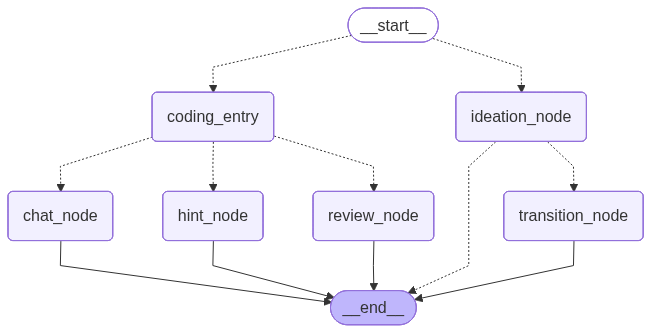

In [12]:
from IPython.display import Image, display
display(Image(mentor_graph.get_graph(xray=True).draw_mermaid_png()))

In [30]:
def make_config(thread_id: str) -> RunnableConfig:
    return RunnableConfig(configurable={"thread_id": thread_id})

async def get_current_state(config: RunnableConfig) -> MentorState:
    state = await mentor_graph.aget_state(config)
    return state.values

async def send_message(message: str, config: dict) -> MentorState:
    """Send one user message, return state after graph completes."""
    await mentor_graph.ainvoke(
        {"messages": [HumanMessage(content=message)]},  # ensure code_submission is reset on new message
        config=config
    )
    return await get_current_state(config)

async def submit_code(code: str, config: dict) -> MentorState:
    await mentor_graph.aupdate_state(config, {"code_submission": code})
    await mentor_graph.ainvoke(
        {"messages": [HumanMessage(content="Please review my code")]},
        config=config
    )
    return await get_current_state(config)


In [31]:
config = make_config("testing_thread_4")
await mentor_graph.ainvoke({
    "problem_description": "Given an array of integers, return indices of the two numbers such that they add up to a specific target. You may assume that each input would have exactly one solution, and you may not use the same element twice.",
    "current_phase": "IDEATION",
    "messages": [HumanMessage(content="Let's start with this problem ")],
},
config=config
)

state = await get_current_state(config)
state

{'messages': [HumanMessage(content="Let's start with this problem ", additional_kwargs={}, response_metadata={}),
  AIMessage(content='To get us started, how would you approach finding these two indices if you were to do it manually with a pen and paper?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 322, 'total_tokens': 349, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'google/gemma-4-26b-a4b-it', 'system_fingerprint': '', 'id': 'e57d4016d2e6eadc49ee21a1efd20e57', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019eab34-8934-7940-84a5-8b13c96e5401-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 322, 'output_tokens': 27, 'total_tokens': 349, 'input_token_details': {}, 'output_token_details': {}})],
 'problem_description': 'Given an array of integers, return indices of the two numbers such that they add up to a specific ta

In [32]:
await send_message("I think we can use a hash map to solve this.", config)

{'messages': [HumanMessage(content="Let's start with this problem ", additional_kwargs={}, response_metadata={}),
  AIMessage(content='To get us started, how would you approach finding these two indices if you were to do it manually with a pen and paper?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 322, 'total_tokens': 349, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'google/gemma-4-26b-a4b-it', 'system_fingerprint': '', 'id': 'e57d4016d2e6eadc49ee21a1efd20e57', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019eab34-8934-7940-84a5-8b13c96e5401-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 322, 'output_tokens': 27, 'total_tokens': 349, 'input_token_details': {}, 'output_token_details': {}}),
  HumanMessage(content='I think we can use a hash map to solve this.', additional_kwargs={}, response_metadata={}),
  AIMessag

In [33]:
await send_message("I think we can use a hash map to store the numbers we've seen so far.", config)

{'messages': [HumanMessage(content="Let's start with this problem ", additional_kwargs={}, response_metadata={}),
  AIMessage(content='To get us started, how would you approach finding these two indices if you were to do it manually with a pen and paper?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 322, 'total_tokens': 349, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'google/gemma-4-26b-a4b-it', 'system_fingerprint': '', 'id': 'e57d4016d2e6eadc49ee21a1efd20e57', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019eab34-8934-7940-84a5-8b13c96e5401-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 322, 'output_tokens': 27, 'total_tokens': 349, 'input_token_details': {}, 'output_token_details': {}}),
  HumanMessage(content='I think we can use a hash map to solve this.', additional_kwargs={}, response_metadata={}),
  AIMessag

In [34]:
await send_message("We can store the number as the key and its index as the value in the hash map. Then for every number, we calculate target - current_number and check if that value already exists in the hash map. If it exists, we return the two indices. Otherwise, we store the current number and continue. Time Complexity: O(n)Space Complexity: O(n)", config)

{'messages': [HumanMessage(content="Let's start with this problem ", additional_kwargs={}, response_metadata={}),
  AIMessage(content='To get us started, how would you approach finding these two indices if you were to do it manually with a pen and paper?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 322, 'total_tokens': 349, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'google/gemma-4-26b-a4b-it', 'system_fingerprint': '', 'id': 'e57d4016d2e6eadc49ee21a1efd20e57', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019eab34-8934-7940-84a5-8b13c96e5401-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 322, 'output_tokens': 27, 'total_tokens': 349, 'input_token_details': {}, 'output_token_details': {}}),
  HumanMessage(content='I think we can use a hash map to solve this.', additional_kwargs={}, response_metadata={}),
  AIMessag

In [35]:
code = """
class Solution:
    def twoSum(self, nums: List[int], target: int) -> List[int]:
        hashMap = {}

        for i, num in enumerate(nums):
            complement = target - num

            if complement in hashMap:
                return [hashMap[complement], i]

            hashMap[num] = i
"""
await submit_code(code,config)


{'messages': [HumanMessage(content="Let's start with this problem ", additional_kwargs={}, response_metadata={}),
  AIMessage(content='To get us started, how would you approach finding these two indices if you were to do it manually with a pen and paper?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 322, 'total_tokens': 349, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'google/gemma-4-26b-a4b-it', 'system_fingerprint': '', 'id': 'e57d4016d2e6eadc49ee21a1efd20e57', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019eab34-8934-7940-84a5-8b13c96e5401-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 322, 'output_tokens': 27, 'total_tokens': 349, 'input_token_details': {}, 'output_token_details': {}}),
  HumanMessage(content='I think we can use a hash map to solve this.', additional_kwargs={}, response_metadata={}),
  AIMessag

In [55]:
get_current_state(config)

{'messages': [HumanMessage(content="Let's start with this problem ", additional_kwargs={}, response_metadata={}),
  AIMessage(content='To get us started, how would you approach finding these two indices if you were to do it manually with a small list of numbers?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 28, 'prompt_tokens': 335, 'total_tokens': 363, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0, 'cache_creation_input_tokens': 0, 'cache_read_input_tokens': 0, 'text_tokens': 0, 'image_tokens': 0, 'video_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'google/gemma-4-26b-a4b-it', 'system_fingerprint': '', 'id': 'dcdd86764332212f71f129fdd24355ec', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019e468a-615c-7443-b594-b94f7a73a172-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 335, 'output_tokens': 28, 'total_tokens': 363, 'input_token_details